In [14]:
# Imports and setup
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingRegressor, RandomForestClassifier)
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")

RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

In [15]:
# Categorical and numerical inputs
CATEGORIC_COLS = ["Airline", "AirportFrom", "AirportTo", "DayOfWeek"]
NUMERIC_COLS = ["Flight", "Time", "Length"]

TARGET = "Delay"
FEATURES = CATEGORIC_COLS + NUMERIC_COLS


def load():
    """Download the flight delay dataset from OpenML (42493) and fix column types."""

    df = fetch_openml(data_id=42493, as_frame=True, parser="liac-arff").frame

    # Convert categorical input to string then pandas category
    for col in CATEGORIC_COLS:
        df[col] = df[col].astype(str).astype("category")

    # Convert numeric inputs to real numbers
    for col in NUMERIC_COLS:
        df[col] = pd.to_numeric(df[col].astype(str))

    df[TARGET] = df[TARGET].astype(str).astype(int)

    return df


def split(df, seed=0):
    """Split the data into fit, calibration, and test."""
    # 80% train / 20% test
    train, test = train_test_split(
        df, test_size=0.2, random_state=seed, stratify=df[TARGET]
    )

    fit, calib = train_test_split(
        train, test_size=1000, random_state=seed, stratify=train[TARGET]
    )

    return (
        fit.reset_index(drop=True),
        calib.reset_index(drop=True),
        test.reset_index(drop=True),
    )


df = load()
fit, calib, test = split(df, seed=0)

print("Peek Data")
print(df.head())

print("\nData shape")
print(df.shape)

print("\nColumn types")
print(df.dtypes.to_string())

print("\nNumber of distinct values per categorical column")
for col in CATEGORIC_COLS:
    print(f"{col} {df[col].nunique()}")

print("\nSplit sizes")
print(f"fit   (train models):       {len(fit)}")
print(f"calib (conformal quantiles): {len(calib)}")
print(f"test  (corrupt + clean):     {len(test)}")

Peek Data
  Airline  Flight AirportFrom AirportTo DayOfWeek   Time  Length  Delay
0      OO    4492         GJT       SLC         6  785.0    56.0      0
1      EV    5364         MGM       MEM         6  375.0    76.0      0
2      FL    1016         BOS       MCO         7  703.0   205.0      0
3      F9     231         BNA       DEN         5  880.0   173.0      0
4      AS     662         SEA       DFW         5  730.0   230.0      0

Data shape
(26969, 8)

Column types
Airline        category
Flight            int64
AirportFrom    category
AirportTo      category
DayOfWeek      category
Time            float64
Length          float64
Delay             int64

Number of distinct values per categorical column
Airline 18
AirportFrom 283
AirportTo 285
DayOfWeek 7

Split sizes
fit   (train models):       20575
calib (conformal quantiles): 1000
test  (corrupt + clean):     5394


In [16]:
# Downstream model: predicts whether a flight is going to be delayed
def build_downstream():
    """Builds classifier used to measure data cleaning quality and returns a GridSearchCV with best settings judged by f1 score."""

    pre = ColumnTransformer([("num", StandardScaler(), NUMERIC_COLS), ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIC_COLS)])
    pipeline = Pipeline([("pre", pre), ("clf", SGDClassifier(random_state=0))])
    grid = {"clf__loss": ["log_loss", "hinge"], "clf__alpha": [1e-5, 1e-4, 1e-3]}

    return GridSearchCV(pipeline, grid, scoring="f1", cv=3, n_jobs=-1)

model = build_downstream().fit(fit[FEATURES], fit[TARGET])

# Print baseline score
f1_clean = f1_score(test[TARGET], model.predict(test[FEATURES]))
print(f"Clean f1 score: {f1_clean:.4f}")

Clean f1 score: 0.5082


In [17]:
"""
4 types of corruption: categorical shift, random scaling, swap airports, and gaussian noise.
F1 scores are then checked again and compared to the clean model. A drop in F1 score means that the corruption mattered
"""

def _prep(df):
    # prepare the data for corruption
    copy = df.copy()

    for col in copy.columns:
        if str(copy[col].dtype) == "category": copy[col] = copy[col].astype(object)
        elif pd.api.types.is_integer_dtype(copy[col]): copy[col] = copy[col].astype(float)

    return copy

def _pick_rows(rng, n_rows, fraction):
    """retuns a boolean array that is true for a fraction of rows"""
    return rng.random(n_rows) < fraction

def _finish(original, corrupted):
    """marks cells when value is different from the original"""
    mask = pd.DataFrame(False, index=original.index, columns=original.columns)

    for col in original.columns:
        if pd.api.types.is_numeric_dtype(original[col]):
          changed = corrupted[col].astype(float) != original[col].astype(float)
        else:
          changed = corrupted[col].astype(str) != original[col].astype(str)

        mask[col] = changed.values

    return corrupted, mask


# Four types of corruption:
def gaussian_noise(test, num_cols, fraction, seed, train_std, scale=3.0):
    """add  gaussian noise"""
    rand = np.random.default_rng(seed)
    res = _prep(test)

    for col in num_cols:
        rows = _pick_rows(rand, len(test), fraction)
        noise = rand.normal(0, train_std[col] * scale, rows.sum())
        res.loc[rows, col] += noise

    return _finish(test, res)


def random_scaling(test, num_cols, fraction, seed, factors=(10, 100, 1000)):
    """scale randomly but 10, 100, or 1000"""
    rand = np.random.default_rng(seed)
    res = _prep(test)

    for col in num_cols:
        rows = _pick_rows(rand, len(test), fraction)
        res.loc[rows, col] *= rand.choice(factors, rows.sum())

    return _finish(test, res)


def swap_columns(test, cols, fraction, seed):
    """swap 2 columns"""
    rand = np.random.default_rng(seed)
    res = _prep(test)
    col_a, col_b = rand.choice(cols, 2, replace=False)
    rows = _pick_rows(rand, len(test), fraction)
    res.loc[rows, [col_a, col_b]] = res.loc[rows, [col_b, col_a]].values

    return _finish(test, res)


def categorical_shift(test, cat_cols, fraction, seed):
    """shift on categorical cells"""
    rand = np.random.default_rng(seed)
    res = _prep(test)

    for col in cat_cols:
        cat = res[col].unique()
        prob = rand.dirichlet(np.ones(len(cat)) * 0.3)
        rows = _pick_rows(rand, len(test), fraction)
        res.loc[rows, col] = rand.choice(cat, rows.sum(), p=prob)

    return _finish(test, res)


# Corruptions
TYPES_OF_CORRUPTIONS = ["gaussian_noise", "random_scaling", "swap_airports", "cat_shift"]

def corrupt(name, test, frac, seed, train_std):
    """applies the corruption and returns named, mask"""
    X = test[FEATURES]
    if name == "gaussian_noise":
        return gaussian_noise(X, NUMERIC_COLS, frac, seed, train_std)
    if name == "random_scaling":
        return random_scaling(X, NUMERIC_COLS, frac, seed)
    if name == "swap_airports":
        return swap_columns(X, ["AirportFrom", "AirportTo"], frac, seed)
    if name == "cat_shift":
        return categorical_shift(X, CATEGORIC_COLS, frac, seed)
    raise ValueError(f"Unknown corruption: {name}")


# check if the corruptions hurt or damadge the downstream model
train_std = fit[NUMERIC_COLS].std()
clean_f1 = f1_score(test[TARGET], model.predict(test[FEATURES]))
rows = []

for name in TYPES_OF_CORRUPTIONS:
    for fraction in (0.1, 0.3, 0.5):
        corr, mask = corrupt(name, test, fraction, seed = 0, train_std = train_std)
        f1 = f1_score(test[TARGET], model.predict(corr))
        rows.append({
            "Corruption": name,
            "Fraction": fraction,
            "Cells_changed": mask.values.mean(),
            "F1": f1,
            "Drop in F1": clean_f1 - f1
        })

print(f"Clean F1: {clean_f1:.4f}\n")
print(pd.DataFrame(rows).round(4).to_string(index=False))

Clean F1: 0.5082

    Corruption  Fraction  Cells_changed     F1  Drop in F1
gaussian_noise       0.1         0.0440 0.5090     -0.0008
gaussian_noise       0.3         0.1249 0.5203     -0.0120
gaussian_noise       0.5         0.2126 0.5098     -0.0016
random_scaling       0.1         0.0437 0.4919      0.0164
random_scaling       0.3         0.1263 0.4747      0.0335
random_scaling       0.5         0.2129 0.4583      0.0500
 swap_airports       0.1         0.0298 0.5081      0.0001
 swap_airports       0.3         0.0849 0.5065      0.0017
 swap_airports       0.5         0.1428 0.5011      0.0071
     cat_shift       0.1         0.0547 0.4976      0.0106
     cat_shift       0.3         0.1573 0.4693      0.0389
     cat_shift       0.5         0.2696 0.4235      0.0848


In [18]:
def calibration_cutoff(scores, alpha):
    """Compute the conformal cutoff from calibration nonconformity scores."""

    n = len(scores)
    if n == 0:
        return np.inf

    # Finite sample adjusted quantile level needed to cover at least 1 - alpha of clean data
    quantile_level = np.ceil((n + 1) * (1 - alpha)) / n

    # if there are too few points for this confidence level
    if quantile_level > 1:
        return np.inf

    return np.quantile(scores, quantile_level, method="higher")

def _hgb(q, seed):
    """Gradient boosting model that predicts the q-th percentile of a number."""

    return HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=seed)

In [19]:
"""
Conformal data cleaner class

Trains one model per column, and it predicts that column from other 6).

Uses clean calibration rows to set a cutoff for each model, then flags
cells in new data that the models find unlikely and replaces them with
the model's best guess.
"""
class CDC:
    def __init__(self, alphas=(0.5, 0.2, 0.001), seed=0):
        # store some settings
        self.alphas = tuple(alphas)
        self.seed = seed

    # helper methods:
    def _encode(self, d):
        """
        Turns a table into a plain grid of numbers for tree models.
        Labels become whole numbers and a label not seen in training turns to -1.
        """
        cat = self.enc.transform(d[CATEGORIC_COLS].astype(str))
        num = d[NUMERIC_COLS].to_numpy(dtype=float)
        encoded_grid = np.hstack([cat, num])

        return encoded_grid

    @staticmethod
    def _others(j):
        # Positions of every column except column j which are inputs for predicting j
        total_columns_temp = len(FEATURES)
        input_columns_temp = []

        for i in range(total_columns_temp):
            if j != i:
                input_columns_temp.append(i)

        return input_columns_temp

    @staticmethod
    def _bounds(low, high, X):
        #Return ordered prediction bounds
        b = high.predict(X)
        a = low.predict(X)

        return np.minimum(a, b), np.maximum(a, b)

    def fit(self, fit_df, calib_df):
        """Train and calibrate the cleaner."""
        # Label -> number dictionary, learned from the training rows only
        self.enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        self.enc.fit(fit_df[CATEGORIC_COLS].astype(str))

        X_fit = self._encode(fit_df)      # training rows -> numbers
        X_calib = self._encode(calib_df)

        # Lookup tables
        self.models = {}
        self.cal = {}
        self.cls_idx = {}

        for j, col in enumerate(FEATURES):
            print(f"  fitting {col} ...", flush=True)
            f = self._others(j)   # inputs = all columns eX_calibept this one

            train_questions = X_fit[:, f]
            train_answers   = fit_df[col]
            calib_questions = X_calib[:, f]
            calib_answers   = calib_df[col]

            if col in CATEGORIC_COLS:
                self.fit_categorical(col, train_questions, train_answers, calib_questions, calib_answers)
            else:
                self.fit_numerical(col, train_questions, train_answers, calib_questions, calib_answers)
        return self


    def fit_categorical(self, col, X, y, X_cal, y_cal):
        """Train and calibrate the model for one label column (e.g. Airline)."""
        y = y.astype(str).to_numpy()

        # Pick the better of 2 model types, comparing on 20% held-out training rows
        X_train, X_val, y_train, y_val = train_test_split(
            X, y, test_size=0.2, random_state=self.seed
        )

        # Small trees keep memory low
        def make_model(model_type):
            return model_type(n_estimators=25, min_samples_leaf=10,
                              n_jobs=1, random_state=self.seed)

        best_model_type = None
        best_score = -1.0

        for model_type in (RandomForestClassifier, ExtraTreesClassifier):
            trial = make_model(model_type).fit(X_train, y_train)
            score = f1_score(y_val, trial.predict(X_val), average="macro")
            if score > best_score:
                best_model_type = model_type
                best_score = score
            del trial

        # Refit the winner on all training rows
        model = make_model(best_model_type).fit(X, y)
        self.models[col] = model
        self.cls_idx[col] = {label: i for i, label in enumerate(model.classes_)}

        # Calibration
        y_cal = y_cal.astype(str).to_numpy()
        keep = np.array([v in self.cls_idx[col] for v in y_cal])
        proba = model.predict_proba(X_cal)[keep]
        true_pos = np.array([self.cls_idx[col][v] for v in y_cal[keep]])
        scores = 1 - proba[np.arange(len(true_pos)), true_pos]

        for alpha in self.alphas:
            cutoffs = np.full(len(model.classes_), calibration_cutoff(scores, alpha))
            for label_pos in np.unique(true_pos):
                label_cutoff = calibration_cutoff(scores[true_pos == label_pos], alpha)
                if np.isfinite(label_cutoff):
                    cutoffs[label_pos] = label_cutoff
            self.cal[(col, alpha)] = cutoffs

    def fit_numerical(self, col, X, y, Xc, yc):
        """
        Fits and trains a model on a numerical column
        Trains a median model for each alpha
        A low and a high quantile model that give a prediction range
        Calibration then widens that range by the right amount
        """
        y = y.to_numpy(dtype=float)
        yc = yc.to_numpy(dtype=float)

        # median model
        self.models[col] = _hgb(0.5, self.seed).fit(X, y)

        for a in self.alphas:
            # gets the low and high models
            low = _hgb(a / 2, self.seed).fit(X, y)
            high = _hgb(1 - a / 2, self.seed).fit(X, y)

            # see how far the true value is outside of the expected range
            low_c, high_c = self._bounds(low, high, Xc)
            scores = np.maximum(low_c - yc, yc - high_c)

            # store the model data
            self.cal[(col, a)] = (low, high, calibration_cutoff(scores, a))

    # Detecting and repair errors
    def clean(self, d, alpha, baseline=False, p=0.5):
        """
        Find suspicious cells in table d and replace them with predictions
        Returns a copy of the data with flagged cells replaced and a table marking the cells we flagged
        """
        data = self._encode(d)

        # make a copy of features from the dataset
        res = d[FEATURES].copy()

        for c in CATEGORIC_COLS:
            res[c] = res[c].astype(object)

        for c in NUMERIC_COLS:
            res[c] = res[c].astype(float)

        flags = pd.DataFrame(False, index=d.index, columns=FEATURES)

        for j, col in enumerate(FEATURES):
            # current col, so the inputs are every col except this one
            data_j = data[:, self._others(j)]

            if col in CATEGORIC_COLS:
                # label the column
                mdl = self.models[col]
                q = self.cal[(col, alpha)]
                prob = mdl.predict_proba(data_j)
                pred = mdl.classes_[prob.argmax(axis = 1)]

                if baseline:
                    # flag it
                    flag = (pred != d[col].astype(str).to_numpy()) & (prob.max(axis = 1) >= p)
                else:
                    # compare to cutoff
                    in_set = (1 - prob) <= q[None, :]

                    observed = np.array([self.cls_idx[col].get(v, -1) for v in d[col].astype(str)])
                    seen = observed >= 0

                    covered = np.zeros(len(d), dtype=bool)
                    covered[seen] = in_set[np.where(seen)[0], observed[seen]]

                    # flag it if it is outside of the set
                    flag = in_set.any(axis=1) & ~covered
            else:
                # it is a numeric column
                low, high, q = self.cal[(col, alpha)]

                if baseline:
                    q = 0.0

                low_p, high_p = self._bounds(low, high, data_j)
                low_i = low_p - q
                high_i = high_p + q

                v = d[col].to_numpy(dtype=float)

                # flag if the observed value is outside of the range
                flag = (low_i <= high_i) & ((v < low_i) | (v > high_i))
                pred = self.models[col].predict(data_j)

            #replace the flagged cells
            res.loc[flag, col] = pred[flag]
            flags[col] = flag

        return res, flags

In [20]:
def detection_rates(flags, mask):
    """returns true positive rate, false positive rate"""
    # flag = flagged cell and mask = true cell with corruption from "answer key"
    flag = flags.to_numpy()
    mask = mask.to_numpy()

    # errors caught and missed
    # calculates TPR
    true_positive = (flag & mask).sum()
    false_negative = (~flag & mask).sum()

    # clean cells that were wrongly flagged or correctly left alone
    # calculates FPR
    false_positive = (flag & ~mask).sum()
    true_negative = (~flag & ~mask).sum()

    return true_positive / max(true_positive + false_negative, 1), false_positive / max(false_positive + true_negative, 1)

In [21]:
# run cdc
cdc = CDC(alphas=(0.5, 0.2, 0.001), seed=0).fit(fit, calib)

#prints clean test flag rate for every column which should be about <= alpha
print("\n Clean test flag rate per column:")\

# print for every alpha value
for a in cdc.alphas:
    _, flags = cdc.clean(test, a)
    print(f"alpha={a}:", flags.mean().round(3).to_dict())


print("\n Detection on corrupted test:")

std = fit[NUMERIC_COLS].std()

for name, (corrupted, mask) in {"gaussian_noise 30%": gaussian_noise(test[FEATURES], NUMERIC_COLS, 0.3, 0, std), "cat_shift 30%": categorical_shift(test[FEATURES], CATEGORIC_COLS, 0.3, 0)}.items():
    for a in cdc.alphas:
        _, flags = cdc.clean(corrupted, a)
        trueposrate, falseposrate = detection_rates(flags, mask)
        print(f"{name:20s} alpha={a:<6} TPR={trueposrate:.3f} FPR={falseposrate:.3f}")

  fitting Airline ...
  fitting AirportFrom ...
  fitting AirportTo ...
  fitting DayOfWeek ...
  fitting Flight ...
  fitting Time ...
  fitting Length ...

 Clean test flag rate per column:
alpha=0.5: {'Airline': 0.046, 'AirportFrom': 0.461, 'AirportTo': 0.445, 'DayOfWeek': 0.473, 'Flight': 0.498, 'Time': 0.501, 'Length': 0.484}
alpha=0.2: {'Airline': 0.097, 'AirportFrom': 0.186, 'AirportTo': 0.191, 'DayOfWeek': 0.162, 'Flight': 0.192, 'Time': 0.209, 'Length': 0.212}
alpha=0.001: {'Airline': 0.0, 'AirportFrom': 0.001, 'AirportTo': 0.001, 'DayOfWeek': 0.001, 'Flight': 0.001, 'Time': 0.001, 'Length': 0.001}

 Detection on corrupted test:
gaussian_noise 30%   alpha=0.5    TPR=0.886 FPR=0.491
gaussian_noise 30%   alpha=0.2    TPR=0.797 FPR=0.281
gaussian_noise 30%   alpha=0.001  TPR=0.519 FPR=0.015
cat_shift 30%        alpha=0.5    TPR=0.722 FPR=0.501
cat_shift 30%        alpha=0.2    TPR=0.748 FPR=0.281
cat_shift 30%        alpha=0.001  TPR=0.164 FPR=0.003


In [22]:
# global vars
TYPES_OF_CORRUPTIONS = ["gaussian_noise", "random_scaling", "swap_airports", "cat_shift"]
FRACTIONS = [0.01, 0.05, 0.1, 0.3, 0.5]
ALPHAS = (0.5, 0.2, 0.001)

# method for corrupting
def corrupt(name, test, frac, seed, std):
    t = test[FEATURES]

    if name == "gaussian_noise":
        return gaussian_noise(t, NUMERIC_COLS, frac, seed, std)

    if name == "random_scaling":
        return random_scaling(t, NUMERIC_COLS, frac, seed)

    if name == "swap_airports":
        return swap_columns(t, ["AirportFrom", "AirportTo"], frac, seed)

    return categorical_shift(t, CATEGORIC_COLS, frac, seed)

# method used to run a seed
def run_seed(seed, corruptions=TYPES_OF_CORRUPTIONS, fractions=FRACTIONS, tag=""):

    # split dataset into test, calibration, and fit
    fit, calib, test = split(df, seed = seed)

    downstream = build_downstream().fit(fit[FEATURES], fit[TARGET])
    cdc = CDC(alphas=ALPHAS, seed=seed).fit(fit, calib)
    std = fit[NUMERIC_COLS].std()
    y = test[TARGET]
    clean_f1 = f1_score(y, downstream.predict(test[FEATURES]))
    res_path = f"{RESULTS_DIR}/results{tag}_seed{seed}.csv"

    rows = []

    for name in corruptions:
        for f in fractions:
            corrupted, mask = corrupt(name, test, f, seed, std)
            corr_f1 = f1_score(y, downstream.predict(corrupted))

            for a in ALPHAS:
                for method in ("cdc", "baseline"):
                    cleaned, flags = cdc.clean(corrupted, a, baseline=(method == "baseline"))
                    trueposrate, falseposrate = detection_rates(flags, mask)

                    rows.append(dict(seed = seed, corruption = name, fraction = f, alpha = a, method = method, f1_clean = clean_f1,
                        f1_corrupted = corr_f1, f1_cleaned = f1_score(y, downstream.predict(cleaned)), tpr = trueposrate, fpr = falseposrate))

            print(f"seed={seed} {name} frac={f} done", flush=True)
            pd.DataFrame(rows).to_csv(res_path, index=False)

    return pd.DataFrame(rows)

In [23]:
run_seed(0)

  fitting Airline ...
  fitting AirportFrom ...
  fitting AirportTo ...
  fitting DayOfWeek ...
  fitting Flight ...
  fitting Time ...
  fitting Length ...
seed=0 gaussian_noise frac=0.01 done
seed=0 gaussian_noise frac=0.05 done
seed=0 gaussian_noise frac=0.1 done
seed=0 gaussian_noise frac=0.3 done
seed=0 gaussian_noise frac=0.5 done
seed=0 random_scaling frac=0.01 done
seed=0 random_scaling frac=0.05 done
seed=0 random_scaling frac=0.1 done
seed=0 random_scaling frac=0.3 done
seed=0 random_scaling frac=0.5 done
seed=0 swap_airports frac=0.01 done
seed=0 swap_airports frac=0.05 done
seed=0 swap_airports frac=0.1 done
seed=0 swap_airports frac=0.3 done
seed=0 swap_airports frac=0.5 done
seed=0 cat_shift frac=0.01 done
seed=0 cat_shift frac=0.05 done
seed=0 cat_shift frac=0.1 done
seed=0 cat_shift frac=0.3 done
seed=0 cat_shift frac=0.5 done


,seed,corruption,fraction,alpha,method,f1_clean,f1_corrupted,f1_cleaned,tpr,fpr
0,0,gaussian_noise,0.01,0.500,cdc,0.508228,0.510165,0.488899,0.878205,0.418196
1,0,gaussian_noise,0.01,0.500,baseline,0.508228,0.510165,0.501577,0.878205,0.232833
2,0,gaussian_noise,0.01,0.200,cdc,0.508228,0.510165,0.486017,0.782051,0.181852
3,0,gaussian_noise,0.01,0.200,baseline,0.508228,0.510165,0.502774,0.788462,0.105739
4,0,gaussian_noise,0.01,0.001,cdc,0.508228,0.510165,0.510875,0.461538,0.001197
...,...,...,...,...,...,...,...,...,...,...
115,0,cat_shift,0.50,0.500,baseline,0.508228,0.423464,0.446265,0.176066,0.375308
116,0,cat_shift,0.50,0.200,cdc,0.508228,0.423464,0.509191,0.722834,0.342132
117,0,cat_shift,0.50,0.200,baseline,0.508228,0.423464,0.444980,0.176066,0.226759
118,0,cat_shift,0.50,0.001,cdc,0.508228,0.423464,0.458423,0.153468,0.003553


In [24]:
run_seed(1)

  fitting Airline ...
  fitting AirportFrom ...
  fitting AirportTo ...
  fitting DayOfWeek ...
  fitting Flight ...
  fitting Time ...
  fitting Length ...
seed=1 gaussian_noise frac=0.01 done
seed=1 gaussian_noise frac=0.05 done
seed=1 gaussian_noise frac=0.1 done
seed=1 gaussian_noise frac=0.3 done
seed=1 gaussian_noise frac=0.5 done
seed=1 random_scaling frac=0.01 done
seed=1 random_scaling frac=0.05 done
seed=1 random_scaling frac=0.1 done
seed=1 random_scaling frac=0.3 done
seed=1 random_scaling frac=0.5 done
seed=1 swap_airports frac=0.01 done
seed=1 swap_airports frac=0.05 done
seed=1 swap_airports frac=0.1 done
seed=1 swap_airports frac=0.3 done
seed=1 swap_airports frac=0.5 done
seed=1 cat_shift frac=0.01 done
seed=1 cat_shift frac=0.05 done
seed=1 cat_shift frac=0.1 done
seed=1 cat_shift frac=0.3 done
seed=1 cat_shift frac=0.5 done


,seed,corruption,fraction,alpha,method,f1_clean,f1_corrupted,f1_cleaned,tpr,fpr
0,1,gaussian_noise,0.01,0.500,cdc,0.518898,0.517561,0.468711,0.869565,0.425592
1,1,gaussian_noise,0.01,0.500,baseline,0.518898,0.517561,0.476697,0.869565,0.233423
2,1,gaussian_noise,0.01,0.200,cdc,0.518898,0.517561,0.465349,0.763975,0.182701
3,1,gaussian_noise,0.01,0.200,baseline,0.518898,0.517561,0.486042,0.770186,0.107056
4,1,gaussian_noise,0.01,0.001,cdc,0.518898,0.517561,0.517814,0.453416,0.001224
...,...,...,...,...,...,...,...,...,...,...
115,1,cat_shift,0.50,0.500,baseline,0.518898,0.420005,0.436737,0.174217,0.368921
116,1,cat_shift,0.50,0.200,cdc,0.518898,0.420005,0.513569,0.719619,0.335906
117,1,cat_shift,0.50,0.200,baseline,0.518898,0.420005,0.454524,0.174217,0.220297
118,1,cat_shift,0.50,0.001,cdc,0.518898,0.420005,0.442504,0.132316,0.002366


In [25]:
run_seed(2)

  fitting Airline ...
  fitting AirportFrom ...
  fitting AirportTo ...
  fitting DayOfWeek ...
  fitting Flight ...
  fitting Time ...
  fitting Length ...
seed=2 gaussian_noise frac=0.01 done
seed=2 gaussian_noise frac=0.05 done
seed=2 gaussian_noise frac=0.1 done
seed=2 gaussian_noise frac=0.3 done
seed=2 gaussian_noise frac=0.5 done
seed=2 random_scaling frac=0.01 done
seed=2 random_scaling frac=0.05 done
seed=2 random_scaling frac=0.1 done
seed=2 random_scaling frac=0.3 done
seed=2 random_scaling frac=0.5 done
seed=2 swap_airports frac=0.01 done
seed=2 swap_airports frac=0.05 done
seed=2 swap_airports frac=0.1 done
seed=2 swap_airports frac=0.3 done
seed=2 swap_airports frac=0.5 done
seed=2 cat_shift frac=0.01 done
seed=2 cat_shift frac=0.05 done
seed=2 cat_shift frac=0.1 done
seed=2 cat_shift frac=0.3 done
seed=2 cat_shift frac=0.5 done


,seed,corruption,fraction,alpha,method,f1_clean,f1_corrupted,f1_cleaned,tpr,fpr
0,2,gaussian_noise,0.01,0.500,cdc,0.575605,0.573549,0.531887,0.826347,0.405469
1,2,gaussian_noise,0.01,0.500,baseline,0.575605,0.573549,0.532118,0.832335,0.230108
2,2,gaussian_noise,0.01,0.200,cdc,0.575605,0.573549,0.535904,0.766467,0.176558
3,2,gaussian_noise,0.01,0.200,baseline,0.575605,0.573549,0.545455,0.766467,0.106089
4,2,gaussian_noise,0.01,0.001,cdc,0.575605,0.573549,0.574046,0.377246,0.001091
...,...,...,...,...,...,...,...,...,...,...
115,2,cat_shift,0.50,0.500,baseline,0.575605,0.450646,0.442767,0.182058,0.383805
116,2,cat_shift,0.50,0.200,cdc,0.575605,0.450646,0.523591,0.733698,0.349277
117,2,cat_shift,0.50,0.200,baseline,0.575605,0.450646,0.455393,0.182058,0.234099
118,2,cat_shift,0.50,0.001,cdc,0.575605,0.450646,0.512144,0.157263,0.002362


                                 tpr    fpr
corruption     method   alpha              
cat_shift      baseline 0.001  0.225  0.018
                        0.200  0.225  0.151
                        0.500  0.225  0.285
               cdc      0.001  0.160  0.002
                        0.200  0.745  0.244
                        0.500  0.728  0.468
gaussian_noise baseline 0.001  0.507  0.021
                        0.200  0.786  0.109
                        0.500  0.876  0.217
               cdc      0.001  0.450  0.011
                        0.200  0.782  0.244
                        0.500  0.873  0.458
random_scaling baseline 0.001  0.967  0.018
                        0.200  0.993  0.109
                        0.500  0.996  0.217
               cdc      0.001  0.966  0.016
                        0.200  0.993  0.261
                        0.500  0.996  0.467
swap_airports  baseline 0.001  0.019  0.012
                        0.200  0.019  0.114
                        0.500  0

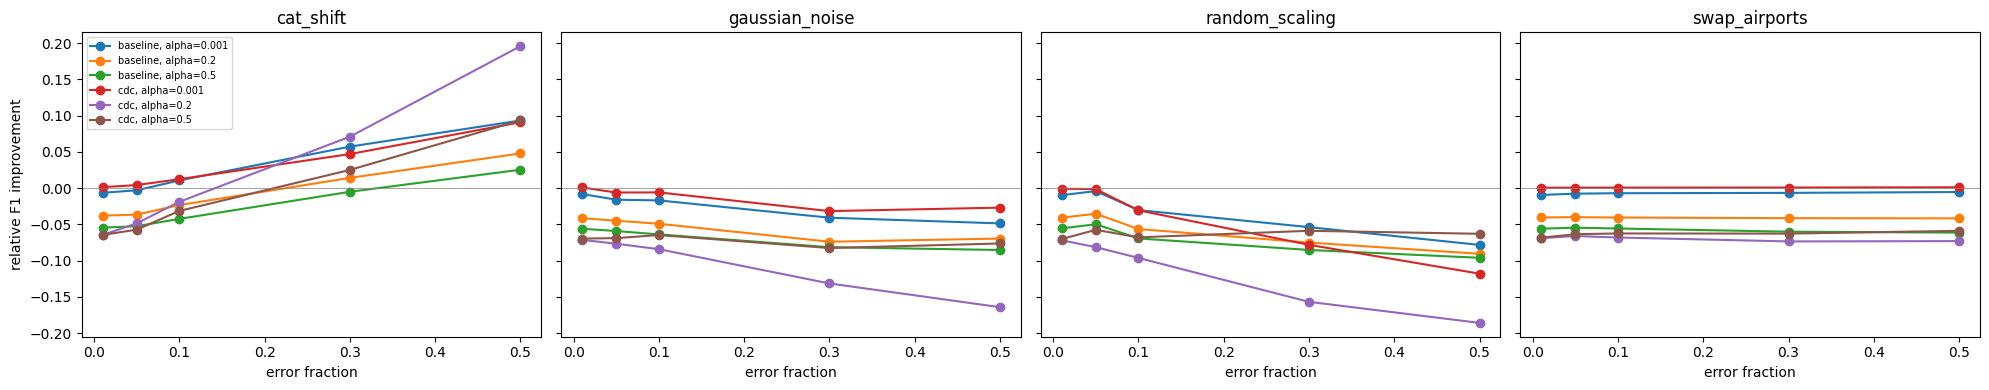

In [26]:
tables = []
for seed in [0, 1, 2]:
    file_path = f"{RESULTS_DIR}/results_seed{seed}.csv"
    tables.append(pd.read_csv(file_path))

res = pd.concat(tables, ignore_index=True)

res["improvement"] = (res.f1_cleaned - res.f1_corrupted) / res.f1_corrupted

print(res.groupby(["corruption", "method", "alpha"])[["tpr", "fpr"]].mean().round(3))

g = res.groupby(["corruption", "method", "alpha", "fraction"]).improvement.mean().reset_index()
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for ax, (name, d) in zip(axes, g.groupby("corruption")):
    for (method, alpha), s in d.groupby(["method", "alpha"]):
        ax.plot(s.fraction, s.improvement, marker="o", label=f"{method}, alpha={alpha}")
    ax.set_title(name)
    ax.set_xlabel("error fraction")
    ax.axhline(0, color="gray", lw=0.5)

axes[0].set_ylabel("relative F1 improvement")
axes[0].legend(fontsize=7)

# draw plot for f1 scores of 4 types of corruption
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/improvement.png", dpi=150)
plt.show()